## Visualizing Fire Scars from the Eaton and Palisades Fires 

# About

# Data Exploration

# Refernces

Importing Packages and Loading Data 

In [39]:
# Import packages 
import pandas as pd 
import os 
import numpy as np 
import geopandas as gpd 
import xarray as xr 
import rioxarray
import matplotlib.pyplot as plt

(2) Fire Perimeter Data Exploration 
Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.

In [40]:
# Import the Eaton data 
eaton_fp = os.path.join('data', 'eaton_data', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(eaton_fp)
eaton.head()

# Find the CRS 
print(f"Eaton CRS:", eaton.crs)

# Seeing if it is projected or geogaphic 
print('Is Eaton geographic?: ', eaton.crs.is_geographic)
print('Is Eaton projected?: ', eaton.crs.is_projected)

Eaton CRS: EPSG:4269
Is Eaton geographic?:  True
Is Eaton projected?:  False


In [41]:
# Import Palisades data 
palisades_fp = os.path.join('data', 'palisades_data', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(palisades_fp)
palisades.head()

# Finding the CRS of the data 
print(f"Palisades CRS", palisades.crs)

# Seeing if it is projected or geographic 
print('Is Palisades geographic?: ', palisades.crs.is_geographic)
print('Is Palisades projected?: ', palisades.crs.is_projected)

Palisades CRS EPSG:4269
Is Palisades geographic?:  True
Is Palisades projected?:  False


<Axes: >

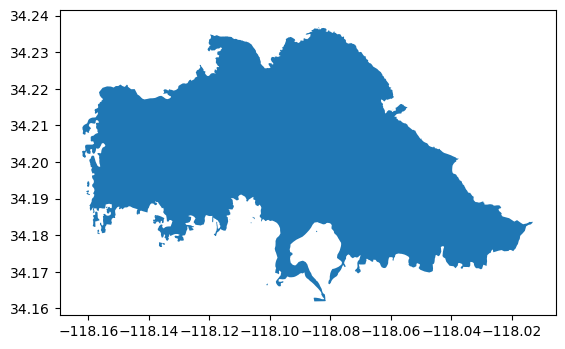

In [42]:
eaton.plot() 

<Axes: >

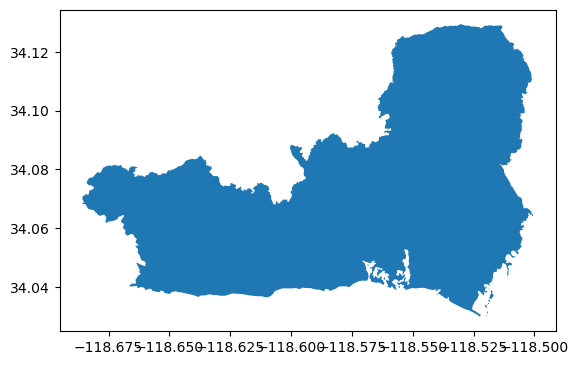

In [43]:
palisades.plot()

Data Exploration Summary: 

(3) NetCDF data import and exploration 

(a) import the Landsat data using xr.open_dataset()

In [44]:
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')
landsat

sh: 1: getfattr: not found


<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

(b) Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data’s variables, dimensions, and coordinates.

(4) Restoring geospatial information 

(a) Use rio.crs to print the CRS of this dataset. Is this a geospatial object? 

In [45]:
print(landsat.rio.crs)

None


(b) You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable spatial_ref. Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset.

In [46]:
print(landsat.spatial_ref.crs_wkt)
landsat_crs = landsat.spatial_ref.crs_wkt

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


(c) Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.

In [47]:
landsat = landsat.rio.write_crs(landsat_crs)

(d) Print the CRS of the updated dataset.

In [48]:
print(landsat.rio.crs)

EPSG:32611


# (5) True Color Image 

(a) Without creating any new variables:
- select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data
- convert it to an xarray.DataArray using the to_dataarray() method, and then
- use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.

(b) Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


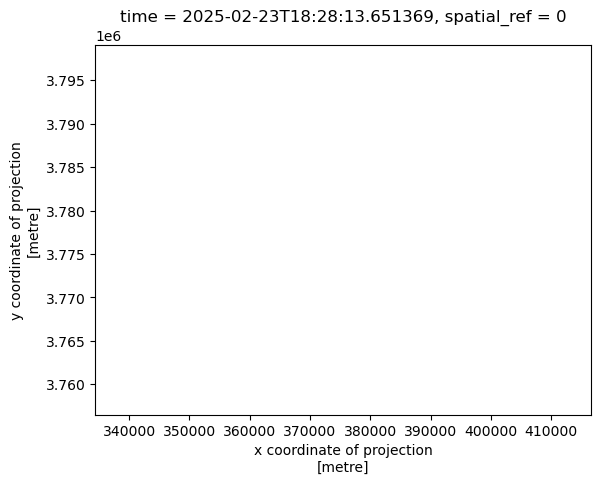

In [49]:
landsat[['red', 'green', 'blue']].to_dataarray(dim='band').plot.imshow(
    x = 'x', 
    y = 'y', 
    rgb = 'band')

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


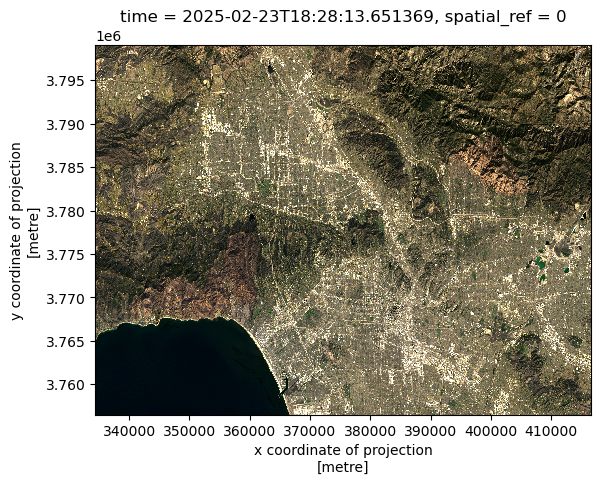

In [50]:
landsat[['red', 'green', 'blue']].to_dataarray(dim='band').plot.imshow(
    x = 'x', 
    y = 'y', 
    rgb = 'band',
    robust = 'True')

(c) To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

In [51]:
# Summing the na values in the landset bands 
np.isnan(landsat).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

(d) Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.

In [52]:
# Replace missing values with zero 
landsat_new = landsat.fillna(0)

(e) Create a new true color image that gets plotted without warnings.

In [57]:
landsat_new[['red', 'green', 'blue']].to_dataarray(dim = 'band').plot.imshow(
    x = 'x', 
    y = 'y', 
    rgb = 'band',
    robust = True)

NameError: name 'ax' is not defined

(f) In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

# (6) False Color Image 
- Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22),  near-infrared, and red variables (in that order).

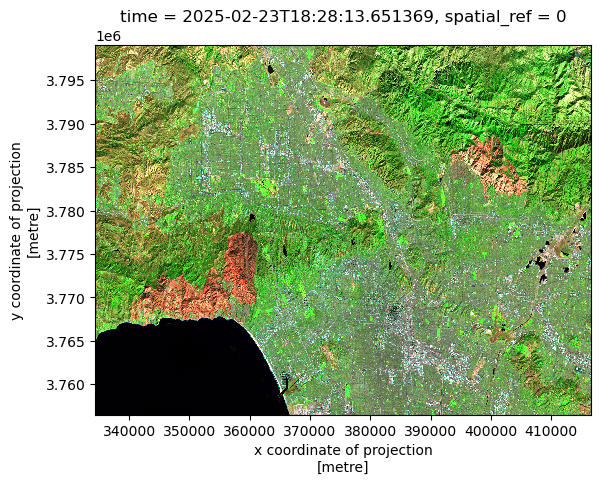

In [54]:
landsat[['swir22', 'nir08', 'red']].to_dataarray(dim = 'band').plot.imshow(
    x = 'x', 
    y = 'y',
    rgb = 'band', 
    robust = True)

# (7) Map 

(a) Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

(b) 
Write a figure description for the map including a brief explanation of how false color imagery is being used.

In [59]:
# Reproject perimiters, match CRS 
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

# match with assert 
assert landsat.rio.crs == eaton.crs
assert landsat.rio.crs == palisades.crs

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


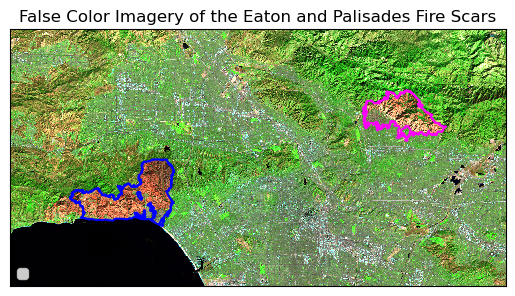

In [63]:
# Plot
fig, ax = plt.subplots()  # Create figure and axes

# False imagery code 
landsat_new[['swir22', 'nir08', 'red']].to_dataarray(dim='band').plot.imshow(
    x = 'x',
    y = 'y',
    rgb = 'band', 
    ax = ax,
    robust = True)

# Perimeters for eaton and palisades 
palisades.boundary.plot(ax=ax, color='blue', linewidth=1.5)
eaton.boundary.plot(ax=ax, color='magenta', linewidth=1.5)

ax.legend(loc = 'lower left')
ax.set_title("False Color Imagery of the Eaton and Palisades Fire Scars")

    
# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

plt.show()